<a href="https://colab.research.google.com/github/814725243084-kk/Exploratory-Analysis-of-youtube-trending-videos/blob/main/EDA%20Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
# pip install pandas numpy matplotlib seaborn wordcloud kagglehub

import os, re, json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from wordcloud import WordCloud

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)

In [32]:
def load_raw_data(filename='USvideos.csv'):
    """Find local CSV or download via kagglehub. Returns (df, data_dir)."""
    candidates = ['.', '/content', '/kaggle/input/youtube-new', os.getcwd()]
    for c in candidates:
        p = os.path.join(c, filename)
        if os.path.exists(p):
            print(f"Found locally: {p}")
            return pd.read_csv(p, encoding='utf-8', on_bad_lines='skip'), c

    print("Not found locally — downloading via kagglehub...")
    import kagglehub
    data_dir = kagglehub.dataset_download("datasnaek/youtube-new")
    if not os.path.exists(os.path.join(data_dir, filename)):
        for root, _, files in os.walk(data_dir):
            if filename in files:
                data_dir = root
                break
    return pd.read_csv(os.path.join(data_dir, filename),
                       encoding='utf-8', on_bad_lines='skip'), data_dir


df_raw, DATA_DIR = load_raw_data()
print(f"Shape: {df_raw.shape}")
df_raw.head()

Not found locally — downloading via kagglehub...
Using Colab cache for faster access to the 'youtube-new' dataset.
Shape: (40949, 16)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


In [33]:
def clean_and_engineer(df_raw, data_dir):
    df = df_raw.copy()

    # Dates
    df['trending_date'] = pd.to_datetime(
        df['trending_date'], format='%y.%d.%m', errors='coerce')
    df['publish_time'] = pd.to_datetime(df['publish_time'], utc=True, errors='coerce')
    df['publish_time_naive'] = df['publish_time'].dt.tz_localize(None)
    df['publish_date'] = df['publish_time_naive'].dt.date
    df['publish_hour'] = df['publish_time_naive'].dt.hour
    df['publish_day']  = df['publish_time_naive'].dt.day_name()
    df['days_to_trend'] = (df['trending_date'] - df['publish_time_naive']).dt.days

    df = df.dropna(subset=['trending_date', 'publish_time_naive']).copy()

    # Engagement
    df['engagement_rate'] = (
        (df['likes'] + df['dislikes'] + df['comment_count'])
        / df['views'].replace(0, np.nan)
    ) * 100
    df['like_ratio'] = df['likes'] / (df['likes'] + df['dislikes']).replace(0, np.nan)

    # Category
    cat_path = os.path.join(data_dir, 'US_category_id.json')
    if os.path.exists(cat_path):
        with open(cat_path) as f:
            cat_map = {int(i['id']): i['snippet']['title']
                       for i in json.load(f)['items']}
    else:
        cat_map = {1:'Film & Animation',2:'Autos & Vehicles',10:'Music',
                   15:'Pets & Animals',17:'Sports',19:'Travel & Events',
                   20:'Gaming',22:'People & Blogs',23:'Comedy',
                   24:'Entertainment',25:'News & Politics',26:'Howto & Style',
                   27:'Education',28:'Science & Technology',
                   29:'Nonprofits & Activism'}
    df['category'] = df['category_id'].map(cat_map)

    # Per-video view
    df_unique = (df.sort_values('trending_date')
                   .drop_duplicates(subset='video_id', keep='first')
                   .copy())
    df_unique['title_len'] = df_unique['title'].astype(str).str.len()
    df_unique['num_tags']  = df_unique['tags'].apply(
        lambda x: len(str(x).split('|')) if pd.notna(x) else 0)

    return df, df_unique


df, df_unique = clean_and_engineer(df_raw, DATA_DIR)
print(f"Records: {len(df):,} | Unique videos: {len(df_unique):,}")
df_unique[['views','likes','comment_count','engagement_rate']].describe()

Records: 40,949 | Unique videos: 6,351


,views,likes,comment_count,engagement_rate
count,6.351000e+03,6.351000e+03,6351.000000,6351.000000
mean,7.582098e+05,3.449357e+04,4501.707290,4.764768
std,1.928993e+06,1.162439e+05,21460.223331,3.898611
min,5.490000e+02,0.000000e+00,0.000000,0.000000
25%,8.351100e+04,1.908000e+03,261.000000,1.924750
50%,2.709020e+05,7.987000e+03,921.000000,3.802762
75%,7.512665e+05,2.516300e+04,2845.000000,6.405392
max,4.843165e+07,3.880071e+06,733373.000000,33.025531


/tmp/ipykernel_2796/3647679236.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette='viridis')


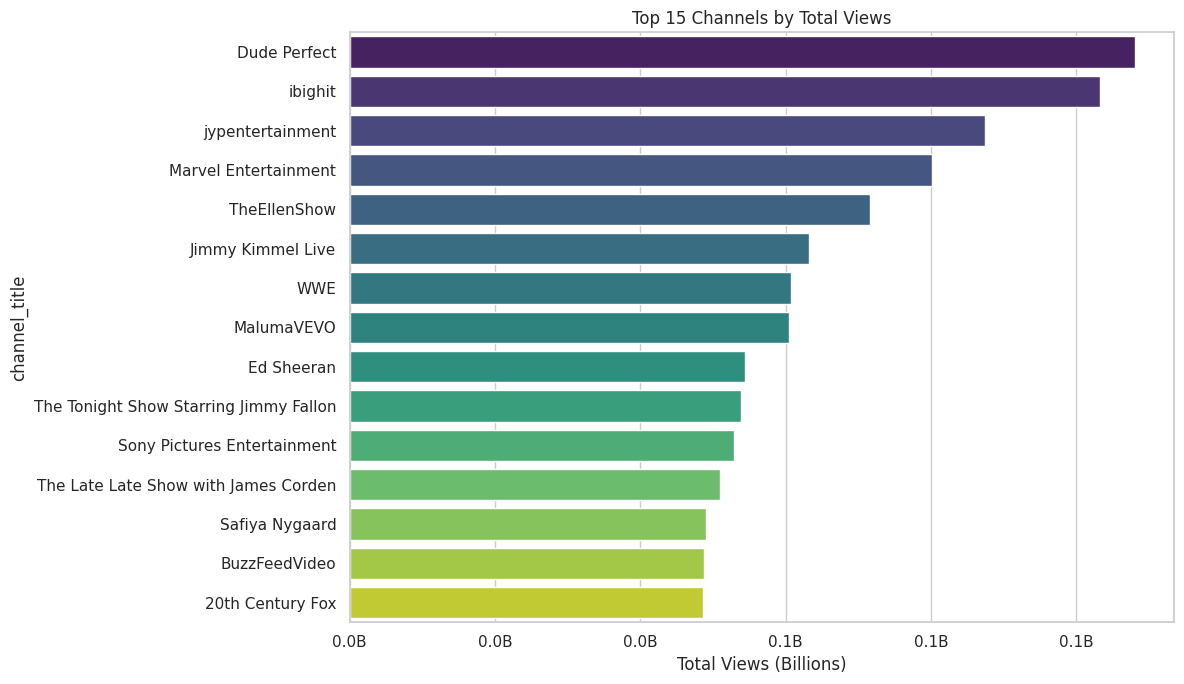

channel_title
Dude Perfect            108024253
ibighit                 103235984
jypentertainment         87356902
Marvel Entertainment     80171420
TheEllenShow             71542914
Name: views, dtype: int64


In [34]:
def top_channels_analysis(df_unique, n=15):
    top = (df_unique.groupby('channel_title')['views']
                     .sum().sort_values(ascending=False).head(n))

    plt.figure(figsize=(12, 7))
    sns.barplot(x=top.values, y=top.index, palette='viridis')
    plt.title(f'Top {n} Channels by Total Views')
    plt.xlabel('Total Views (Billions)')
    plt.gca().xaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'{x/1e9:.1f}B'))
    plt.tight_layout()
    plt.show()
    return top


top_ch = top_channels_analysis(df_unique)
print(top_ch.head())

/tmp/ipykernel_2796/3866058781.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=axes[0], palette='Set2')
/tmp/ipykernel_2796/3866058781.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=views.values, y=views.index, ax=axes[1], palette='Set2')


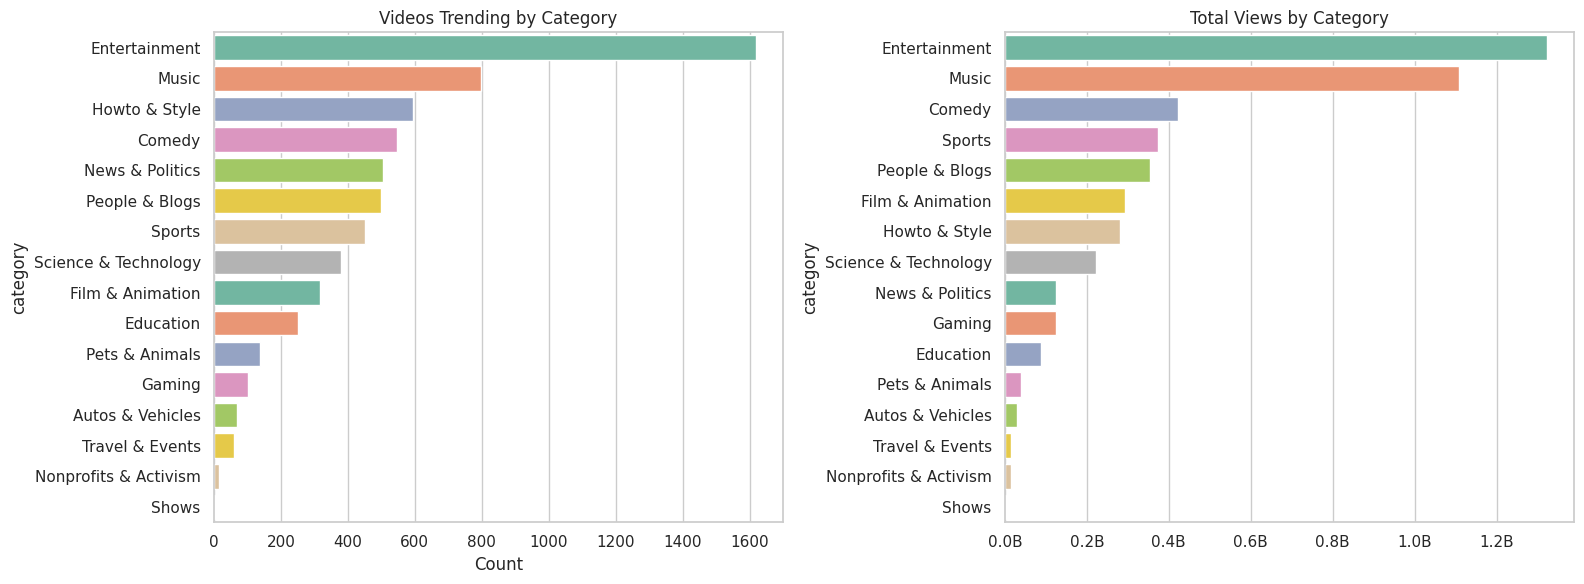

In [35]:
def category_analysis(df_unique):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    counts = df_unique['category'].value_counts()
    sns.barplot(x=counts.values, y=counts.index, ax=axes[0], palette='Set2')
    axes[0].set_title('Videos Trending by Category')
    axes[0].set_xlabel('Count')

    views = df_unique.groupby('category')['views'].sum().sort_values(ascending=False)
    sns.barplot(x=views.values, y=views.index, ax=axes[1], palette='Set2')
    axes[1].set_title('Total Views by Category')
    axes[1].xaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'{x/1e9:.1f}B'))

    plt.tight_layout()
    plt.show()
    return counts, views


cat_counts, cat_views = category_analysis(df_unique)

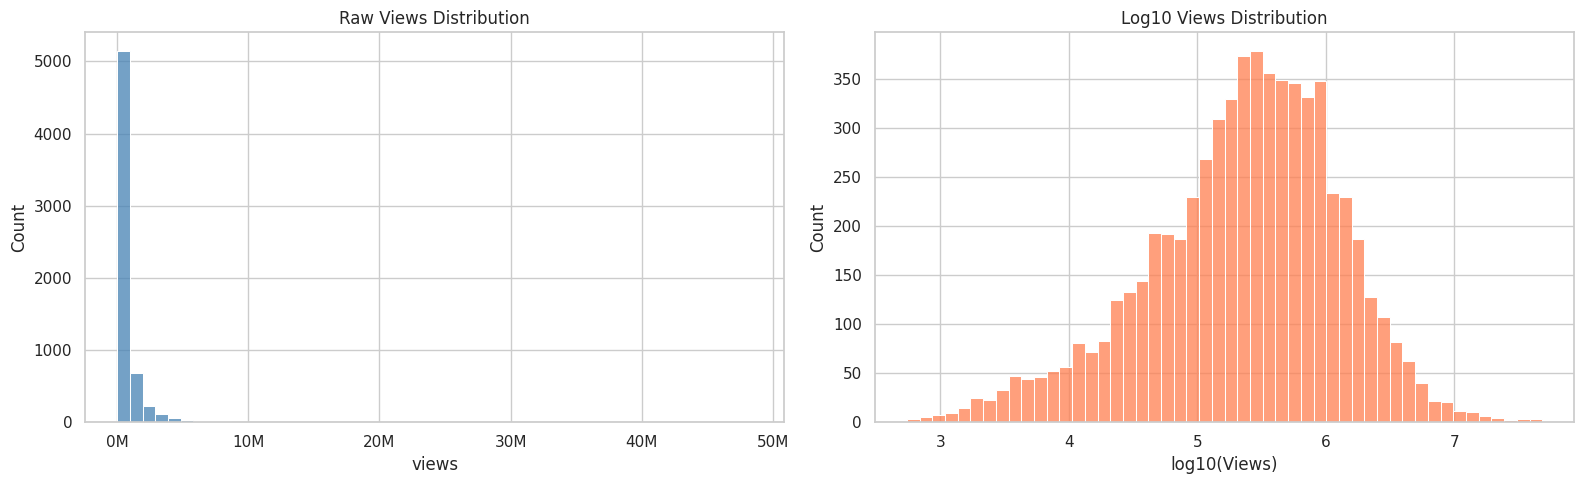

count    6.351000e+03
mean     7.582098e+05
std      1.928993e+06
min      5.490000e+02
25%      8.351100e+04
50%      2.709020e+05
75%      7.512665e+05
max      4.843165e+07
Name: views, dtype: float64


In [36]:
def views_distribution(df_unique):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    sns.histplot(df_unique['views'], bins=50, ax=axes[0], color='steelblue')
    axes[0].set_title('Raw Views Distribution')
    axes[0].xaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))

    sns.histplot(np.log10(df_unique['views'].replace(0, np.nan).dropna()),
                 bins=50, ax=axes[1], color='coral')
    axes[1].set_title('Log10 Views Distribution')
    axes[1].set_xlabel('log10(Views)')

    plt.tight_layout()
    plt.show()
    print(df_unique['views'].describe())


views_distribution(df_unique)

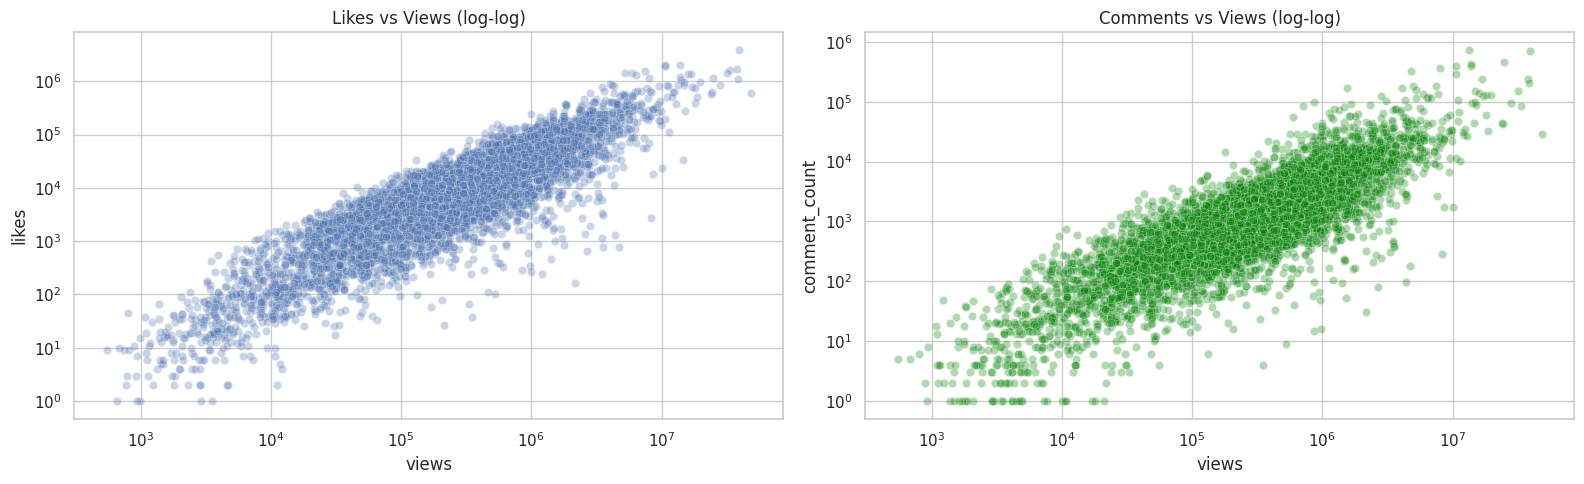

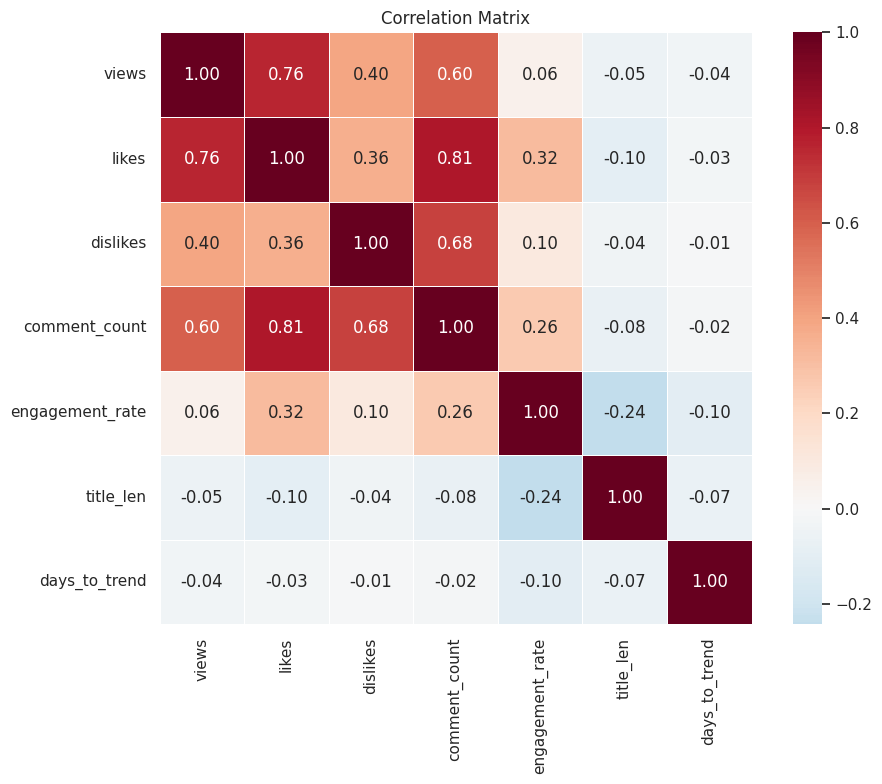

In [37]:
def engagement_analysis(df_unique):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    sns.scatterplot(data=df_unique, x='views', y='likes', alpha=0.3, ax=axes[0])
    axes[0].set_xscale('log'); axes[0].set_yscale('log')
    axes[0].set_title('Likes vs Views (log-log)')

    sns.scatterplot(data=df_unique, x='views', y='comment_count',
                    alpha=0.3, color='green', ax=axes[1])
    axes[1].set_xscale('log'); axes[1].set_yscale('log')
    axes[1].set_title('Comments vs Views (log-log)')
    plt.tight_layout(); plt.show()

    # Heatmap
    cols = ['views','likes','dislikes','comment_count',
            'engagement_rate','title_len','days_to_trend']
    corr = df_unique[cols].corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, square=True, linewidths=0.5)
    plt.title('Correlation Matrix')
    plt.tight_layout(); plt.show()
    return corr


corr_matrix = engagement_analysis(df_unique)

/tmp/ipykernel_2796/321500956.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ttt, x='days_to_trend', y='category',


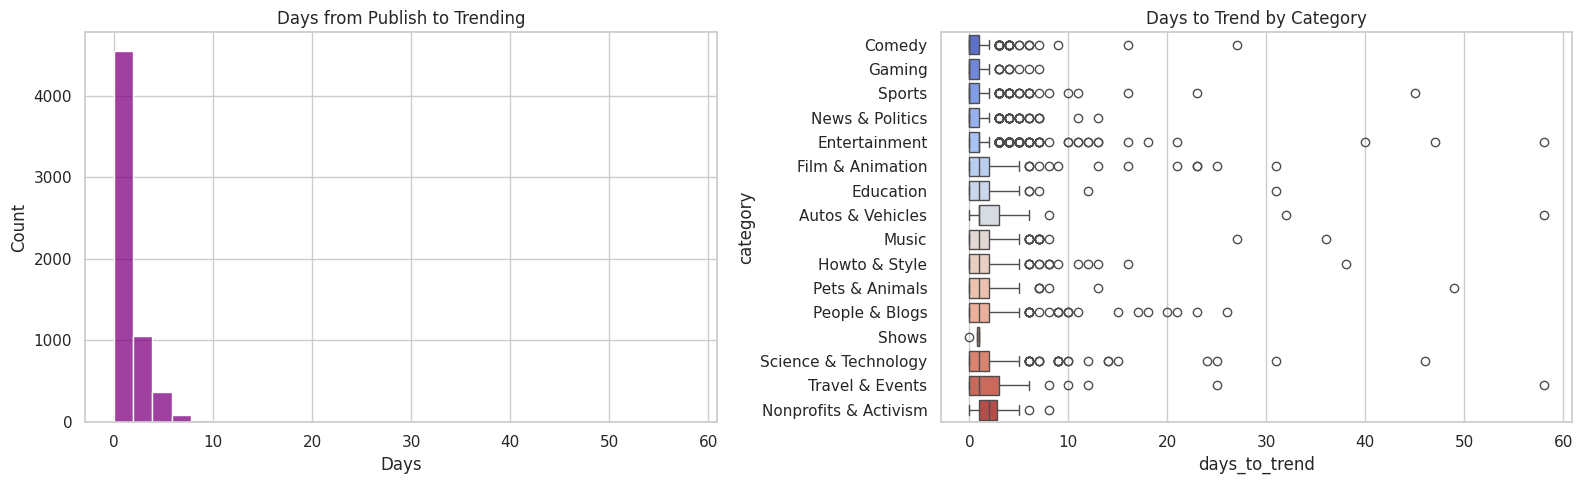

Median days to trend: 1
% within 24h: 74.1%


In [38]:
def time_to_trend_analysis(df_unique, max_days=60):
    ttt = df_unique[df_unique['days_to_trend'].between(0, max_days)]

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    sns.histplot(ttt['days_to_trend'], bins=30, ax=axes[0], color='purple')
    axes[0].set_title('Days from Publish to Trending')
    axes[0].set_xlabel('Days')

    order = ttt.groupby('category')['days_to_trend'].median().sort_values().index
    sns.boxplot(data=ttt, x='days_to_trend', y='category',
                order=order, ax=axes[1], palette='coolwarm')
    axes[1].set_title('Days to Trend by Category')
    plt.tight_layout(); plt.show()

    print(f"Median days to trend: {ttt['days_to_trend'].median():.0f}")
    print(f"% within 24h: {(ttt['days_to_trend']<=1).mean()*100:.1f}%")
    return ttt


ttt = time_to_trend_analysis(df_unique)

/tmp/ipykernel_2796/3968284038.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daily.index, y=daily.values, ax=axes[1], palette='mako')


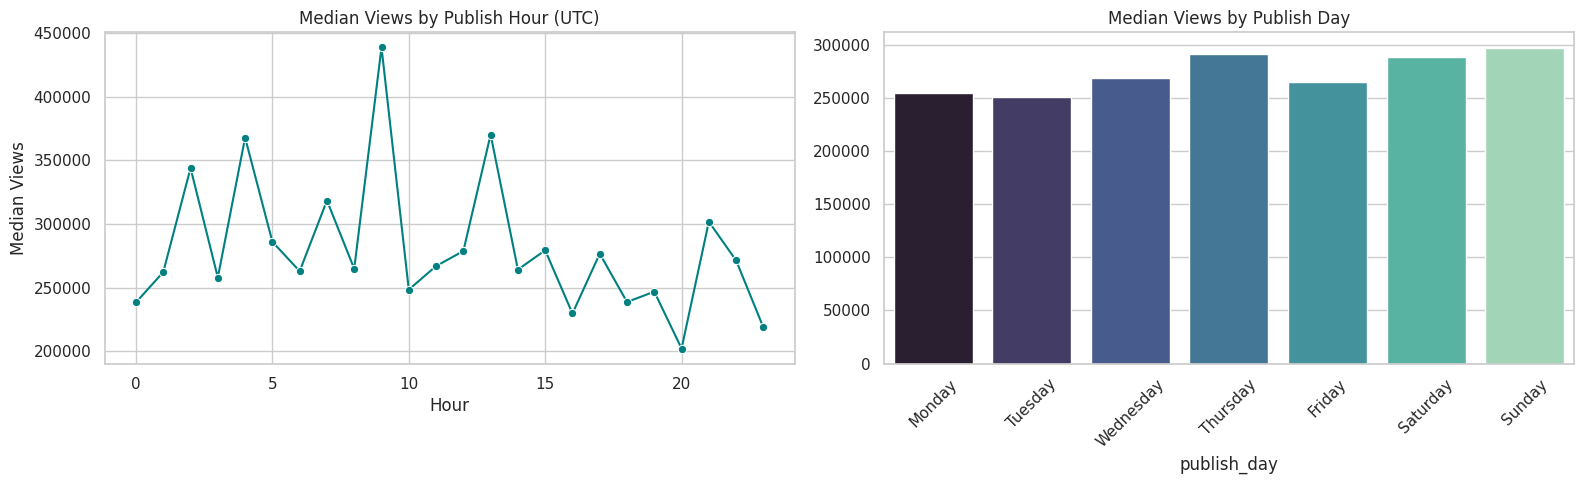

Best hour: 9:00 UTC
Best day : Sunday


In [39]:
def publish_time_analysis(df_unique):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    hourly = df_unique.groupby('publish_hour')['views'].median()
    sns.lineplot(x=hourly.index, y=hourly.values, marker='o',
                 ax=axes[0], color='teal')
    axes[0].set_title('Median Views by Publish Hour (UTC)')
    axes[0].set_xlabel('Hour'); axes[0].set_ylabel('Median Views')

    order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
    daily = df_unique.groupby('publish_day')['views'].median().reindex(order)
    sns.barplot(x=daily.index, y=daily.values, ax=axes[1], palette='mako')
    axes[1].set_title('Median Views by Publish Day')
    axes[1].tick_params(axis='x', rotation=45)
    plt.tight_layout(); plt.show()
    return hourly, daily


hourly_views, daily_views = publish_time_analysis(df_unique)
print(f"Best hour: {hourly_views.idxmax()}:00 UTC")
print(f"Best day : {daily_views.idxmax()}")

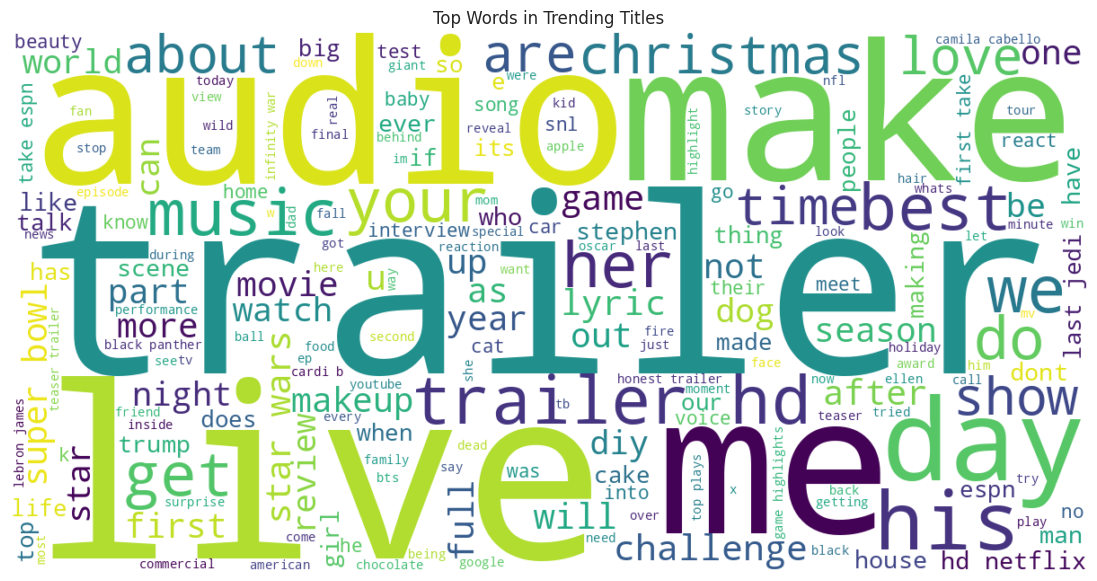

In [40]:
def title_wordcloud(df_unique):
    text = ' '.join(df_unique['title'].astype(str))
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())

    stops = set(['the','a','an','and','of','to','in','on','for','with','my',
                 'you','i','is','it','this','that','at','by','from','official',
                 'video','ft','feat','vs','new','how','what','why','all'])

    wc = WordCloud(width=1200, height=600, background_color='white',
                   stopwords=stops, colormap='viridis').generate(text)
    plt.figure(figsize=(14, 7))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title('Top Words in Trending Titles')
    plt.show()


title_wordcloud(df_unique)

/tmp/ipykernel_2796/2847485036.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_df, x='count', y='tag', palette='rocket')


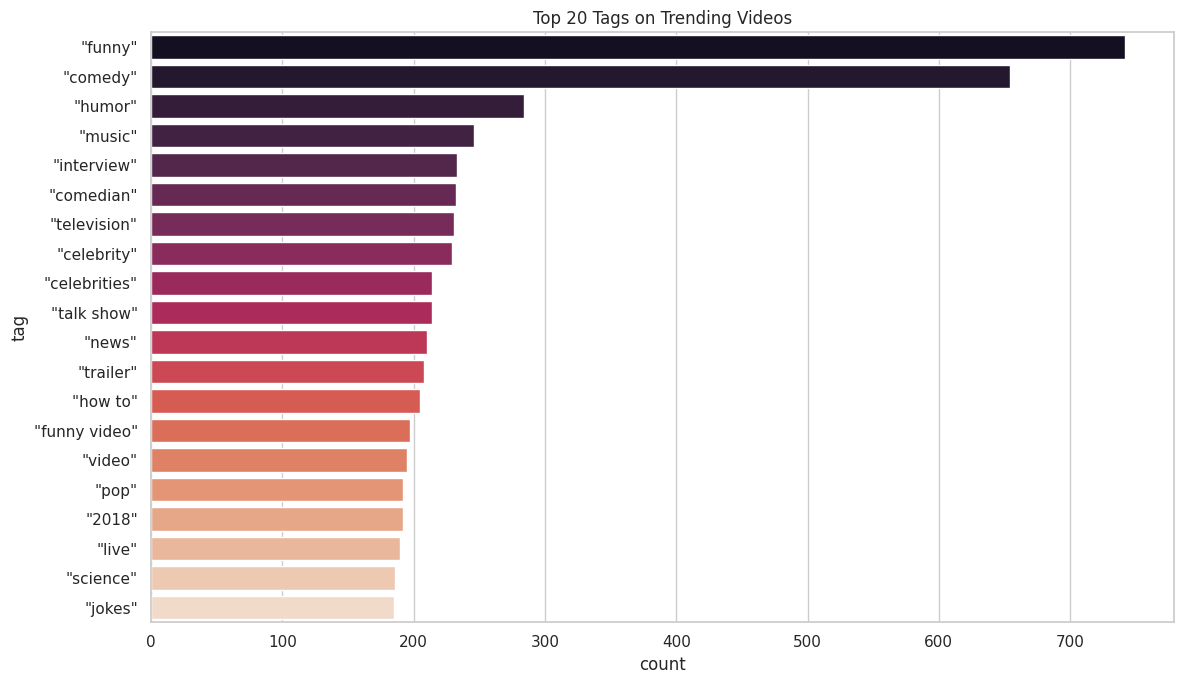

/tmp/ipykernel_2796/2847485036.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_unique, x=bins, y='views', palette='crest')


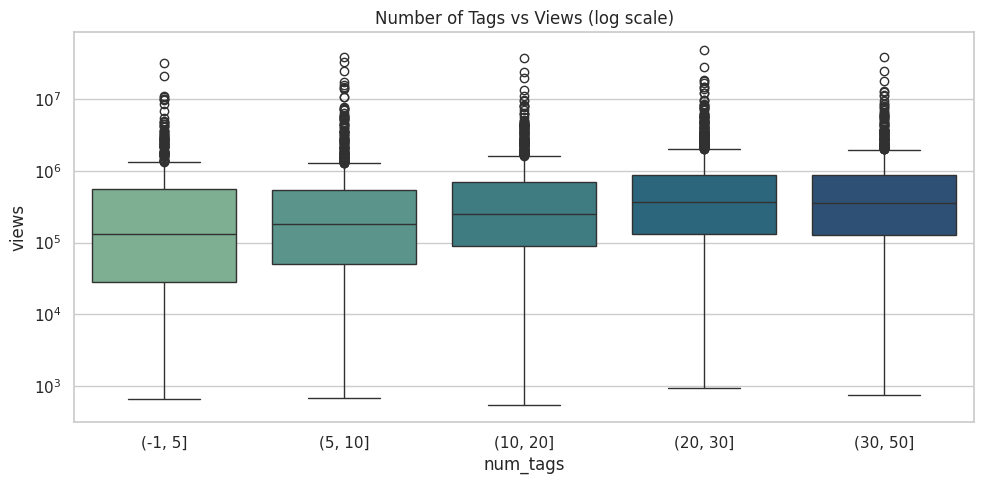

In [41]:
def tags_analysis(df_unique, top_n=20):
    series = df_unique['tags'].dropna().astype(str).str.split('|')
    flat = [t.strip().lower() for s in series for t in s
            if t.strip() and t.strip() != '[none]']
    top = Counter(flat).most_common(top_n)
    top_df = pd.DataFrame(top, columns=['tag','count'])

    plt.figure(figsize=(12, 7))
    sns.barplot(data=top_df, x='count', y='tag', palette='rocket')
    plt.title(f'Top {top_n} Tags on Trending Videos')
    plt.tight_layout(); plt.show()

    # Sweet-spot: number of tags vs views
    plt.figure(figsize=(10, 5))
    bins = pd.cut(df_unique['num_tags'], bins=[-1,5,10,20,30,50])
    sns.boxplot(data=df_unique, x=bins, y='views', palette='crest')
    plt.yscale('log')
    plt.title('Number of Tags vs Views (log scale)')
    plt.tight_layout(); plt.show()
    return top_df


tags_df = tags_analysis(df_unique)

In [42]:
def print_summary():
    print("=" * 60)
    print("KEY INSIGHTS")
    print("=" * 60)
    print(f"• Records:                 {len(df):,}")
    print(f"• Unique videos:           {len(df_unique):,}")
    print(f"• Top category (views):    {cat_views.index[0]}")
    print(f"• Top channel:             {top_ch.index[0]} "
          f"({top_ch.iloc[0]/1e9:.2f}B views)")
    print(f"• Median views:            {df_unique['views'].median():,.0f}")
    print(f"• 90th pct views:          {df_unique['views'].quantile(0.9):,.0f}")
    print(f"• % trending within 24h:   {(ttt['days_to_trend']<=1).mean()*100:.1f}%")
    print(f"• Mean engagement rate:    {df_unique['engagement_rate'].mean():.2f}%")
    print(f"• Best publish hour:       {hourly_views.idxmax()}:00 UTC")
    print(f"• Views/Likes correlation: {corr_matrix.loc['views','likes']:.2f}")


print_summary()

KEY INSIGHTS
• Records:                 40,949
• Unique videos:           6,351
• Top category (views):    Entertainment
• Top channel:             Dude Perfect (0.11B views)
• Median views:            270,902
• 90th pct views:          1,685,423
• % trending within 24h:   74.1%
• Mean engagement rate:    4.76%
• Best publish hour:       9:00 UTC
• Views/Likes correlation: 0.76
